<a href="https://colab.research.google.com/github/bellDataSc/Analise-de-Sentimentos/blob/main/InferenciaLaya.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Testando o Laya em português

Nos meus estudos de sentimento com os roteiros de Rick and Morty, usei dicionários (AFINN, Bing e NRC). Eles são fáceis de auditar, mas não entendem negação: a palavra positiva continua contando, mesmo com um "não" na frente.

O Laya é um modelo de decisão com pesos abertos. Ele recebe um texto e uma pergunta tipada e devolve a resposta com probabilidades, sem gerar texto. Antes de levar o modelo para os roteiros, testei frases curtas em português com duas perguntas: se duas frases têm o mesmo significado e qual é o sentimento de uma frase. São dez frases por pergunta: uma primeira conversa com o modelo, não um benchmark.

Rodei no Colab, com GPU T4 e laya 0.4.13, em 22/10/2026. As probabilidades estão em `resultados/`, e o notebook lê desse arquivo. Para rodar o modelo de novo, mude `RODAR_MODELO` para `True`.

Repositório do Laya: https://github.com/NandhaKishorM/laya

In [1]:
import importlib.util
import os
import subprocess
import sys
from datetime import date
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter

RODAR_MODELO = False
VERSAO_LAYA = "0.4.13"
ARQUIVO = Path("resultados/laya_colab_2026-10-22.csv")
URL = "https://raw.githubusercontent.com/bellDataSc/Analise-de-Sentimentos/main/resultados/laya_colab_2026-10-22.csv"
LIMITE_REVISAO = 0.60

pd.set_option("display.max_colwidth", None)

In [2]:
SIMILARIDADE = [
    ("O paciente está com febre.", "O paciente apresenta temperatura corporal elevada.", "alta"),
    ("O médico prescreveu antibióticos para o paciente.", "O paciente recebeu uma prescrição de antibióticos.", "alta"),
    ("A consulta foi cancelada.", "A consulta não acontecerá conforme planejado.", "alta"),
    ("O paciente está com febre.", "O paciente está com dor de cabeça.", "baixa"),
    ("O paciente recebeu antibióticos.", "O paciente foi tratado por uma infecção.", "média"),
    ("O hospital realizou uma cirurgia.", "O paciente passou por um procedimento médico.", "média"),
    ("O paciente está com febre.", "O paciente não apresenta febre.", "baixa"),
    ("O paciente recebeu antibióticos.", "O paciente recebeu analgésicos.", "baixa"),
    ("O paciente recebeu alta do hospital.", "O paciente foi internado no hospital.", "baixa"),
    ("O médico solicitou um exame de sangue.", "O paciente comprou um computador novo.", "baixa"),
]

SENTIMENTO = [
    ("Adorei o atendimento, foram muito atenciosos.", "positivo"),
    ("O produto chegou antes do prazo e funciona perfeitamente.", "positivo"),
    ("Estou muito satisfeita com a qualidade do serviço.", "positivo"),
    ("A experiência foi excelente, voltaria a comprar.", "positivo"),
    ("O produto chegou, mas ainda não tive tempo de testá-lo.", "neutro"),
    ("A entrega está prevista para amanhã.", "neutro"),
    ("O aplicativo foi atualizado ontem.", "neutro"),
    ("O atendimento foi péssimo e demoraram horas para responder.", "negativo"),
    ("Estou muito decepcionada com a qualidade do produto.", "negativo"),
    ("O pedido chegou quebrado e ninguém resolveu o problema.", "negativo"),
]

PERGUNTA_SIMILARIDADE = {
    "type": "noul",
    "instructions": "As duas frases têm o mesmo significado?",
}

PERGUNTA_SENTIMENTO = {
    "type": "choice",
    "instructions": "Qual é o sentimento predominante no texto?",
    "criteria": {
        "positivo": "O texto expressa um sentimento ou opinião positiva.",
        "neutro": "O texto é neutro e não expressa uma opinião ou emoção claramente positiva ou negativa.",
        "negativo": "O texto expressa um sentimento ou opinião negativa.",
    },
}

TESTES = {
    "similaridade": ("similar", PERGUNTA_SIMILARIDADE, SIMILARIDADE),
    "sentimento": ("sentiment", PERGUNTA_SENTIMENTO, [(texto, "", esperado) for texto, esperado in SENTIMENTO]),
}

In [3]:
def rodar_laya():
    os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")
    os.environ.setdefault("HF_HUB_VERBOSITY", "error")
    if importlib.util.find_spec("laya") is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", f"laya=={VERSAO_LAYA}"], check=True)
    from laya import Router

    router = Router()
    linhas = []
    for teste, (chave, pergunta, casos) in TESTES.items():
        for caso, (texto, texto_b, esperado) in enumerate(casos, 1):
            entrada = f"Frase A: {texto}\nFrase B: {texto_b}" if texto_b else texto
            resposta = router.predict(entrada, {chave: pergunta})["answers"][chave]
            if pergunta["type"] == "noul":
                probabilidades = {"sim": resposta["noul"]}
            else:
                probabilidades = resposta["probabilities"]
            for opcao, probabilidade in probabilidades.items():
                linhas.append({
                    "teste": teste,
                    "caso": caso,
                    "texto": texto,
                    "texto_b": texto_b,
                    "esperado": esperado,
                    "opcao": opcao,
                    "probabilidade": probabilidade,
                })
    return pd.DataFrame(linhas)


if RODAR_MODELO:
    resultados = rodar_laya()
    ARQUIVO = Path(f"resultados/laya_{date.today():%Y-%m-%d}.csv")
    ARQUIVO.parent.mkdir(exist_ok=True)
    resultados.to_csv(ARQUIVO, index=False)
    fonte = ARQUIVO
else:
    fonte = ARQUIVO if ARQUIVO.exists() else URL
    resultados = pd.read_csv(fonte, keep_default_na=False)

definidas = {(teste, texto, texto_b) for teste, (_, _, casos) in TESTES.items() for texto, texto_b, _ in casos}
no_arquivo = set(resultados[["teste", "texto", "texto_b"]].itertuples(index=False, name=None))
if definidas != no_arquivo:
    raise ValueError("As frases do arquivo não batem com as definidas acima. Rode o modelo de novo com RODAR_MODELO = True.")

print(f"{len(no_arquivo)} frases lidas de {fonte}")

20 frases lidas de resultados/laya_colab_2026-10-22.csv


In [4]:
def pct(valor):
    return f"{valor:.2%}".replace(".", ",")


def decisoes(teste):
    dados = resultados[resultados["teste"] == teste].sort_values(["caso", "probabilidade"], ascending=[True, False])
    linhas = []
    for _, grupo in dados.groupby("caso"):
        escolhida, segunda = grupo.iloc[0], grupo.iloc[1]
        linhas.append({
            "Frase": escolhida["texto"],
            "Eu esperava": escolhida["esperado"],
            "Laya": escolhida["opcao"],
            "Confiança": escolhida["probabilidade"],
            "Segunda opção": f"{segunda['opcao']} ({pct(segunda['probabilidade'])})",
            "Acertou": escolhida["opcao"] == escolhida["esperado"],
        })
    return pd.DataFrame(linhas, index=range(1, len(linhas) + 1))


def mostrar(tabela):
    return tabela.assign(**{
        "Confiança": tabela["Confiança"].map(pct),
        "Acertou": tabela["Acertou"].map({True: "sim", False: "não"}),
    })

## As duas frases têm o mesmo significado?

In [5]:
pares = resultados[resultados["teste"] == "similaridade"].sort_values("caso")
pd.DataFrame(
    {
        "Frase A": pares["texto"].to_numpy(),
        "Frase B": pares["texto_b"].to_numpy(),
        "Eu esperava": pares["esperado"].to_numpy(),
        "Mesmo significado": pares["probabilidade"].map(pct).to_numpy(),
    },
    index=range(1, len(pares) + 1),
)

,Frase A,Frase B,Eu esperava,Mesmo significado
1,O paciente está com febre.,O paciente apresenta temperatura corporal elevada.,alta,"93,44%"
2,O médico prescreveu antibióticos para o paciente.,O paciente recebeu uma prescrição de antibióticos.,alta,"99,63%"
3,A consulta foi cancelada.,A consulta não acontecerá conforme planejado.,alta,"28,95%"
4,O paciente está com febre.,O paciente está com dor de cabeça.,baixa,"88,81%"
5,O paciente recebeu antibióticos.,O paciente foi tratado por uma infecção.,média,"85,25%"
6,O hospital realizou uma cirurgia.,O paciente passou por um procedimento médico.,média,"99,51%"
7,O paciente está com febre.,O paciente não apresenta febre.,baixa,"2,95%"
8,O paciente recebeu antibióticos.,O paciente recebeu analgésicos.,baixa,"95,25%"
9,O paciente recebeu alta do hospital.,O paciente foi internado no hospital.,baixa,"36,69%"
10,O médico solicitou um exame de sangue.,O paciente comprou um computador novo.,baixa,"12,87%"


## Qual é o sentimento predominante?

In [6]:
sentimento = decisoes("sentimento")
mostrar(sentimento)

,Frase,Eu esperava,Laya,Confiança,Segunda opção,Acertou
1,"Adorei o atendimento, foram muito atenciosos.",positivo,neutro,"54,13%","positivo (44,81%)",não
2,O produto chegou antes do prazo e funciona perfeitamente.,positivo,positivo,"94,84%","neutro (4,83%)",sim
3,Estou muito satisfeita com a qualidade do serviço.,positivo,positivo,"99,56%","neutro (0,42%)",sim
4,"A experiência foi excelente, voltaria a comprar.",positivo,positivo,"83,92%","neutro (14,35%)",sim
5,"O produto chegou, mas ainda não tive tempo de testá-lo.",neutro,negativo,"48,79%","neutro (42,76%)",não
6,A entrega está prevista para amanhã.,neutro,neutro,"79,20%","negativo (12,48%)",sim
7,O aplicativo foi atualizado ontem.,neutro,negativo,"58,26%","neutro (27,46%)",não
8,O atendimento foi péssimo e demoraram horas para responder.,negativo,negativo,"99,48%","neutro (0,43%)",sim
9,Estou muito decepcionada com a qualidade do produto.,negativo,negativo,"99,85%","neutro (0,13%)",sim
10,O pedido chegou quebrado e ninguém resolveu o problema.,negativo,negativo,"93,42%","neutro (4,08%)",sim


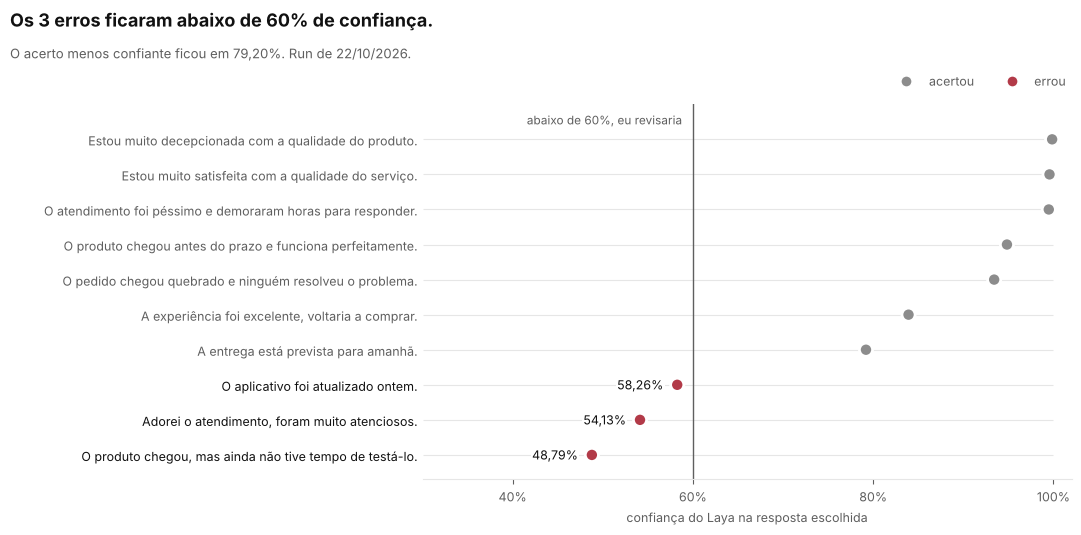

In [7]:
SUPERFICIE = "#FFFFFF"
TINTA = "#111111"
TINTA_SUAVE = "#5F5F5F"
GRADE = "#E6E6E6"
COR_ACERTO = "#8C8C8C"
COR_ERRO = "#B23A48"

ordenada = sentimento.sort_values("Confiança").reset_index(drop=True)
errados = ordenada[~ordenada["Acertou"]]
abaixo = int((errados["Confiança"] < LIMITE_REVISAO).sum())
if abaixo == len(errados):
    titulo = f"Os {len(errados)} erros ficaram abaixo de {LIMITE_REVISAO:.0%} de confiança."
else:
    titulo = f"{abaixo} dos {len(errados)} erros ficaram abaixo de {LIMITE_REVISAO:.0%} de confiança."
menor_acerto = ordenada.loc[ordenada["Acertou"], "Confiança"].min()
data_run = date.fromisoformat(Path(ARQUIVO).stem.split("_")[-1]).strftime("%d/%m/%Y")

fig, eixo = plt.subplots(figsize=(11, 5.6), facecolor=SUPERFICIE)
eixo.set_facecolor(SUPERFICIE)
eixo.hlines(ordenada.index, 0.3, 1.0, color=GRADE, linewidth=0.8, zorder=1)
eixo.axvline(LIMITE_REVISAO, color=TINTA_SUAVE, linewidth=1, zorder=2)
eixo.scatter(
    ordenada["Confiança"],
    ordenada.index,
    s=90,
    c=ordenada["Acertou"].map({True: COR_ACERTO, False: COR_ERRO}).tolist(),
    edgecolors=SUPERFICIE,
    linewidths=2,
    zorder=3,
)
for posicao, linha in errados.iterrows():
    eixo.annotate(
        pct(linha["Confiança"]),
        (linha["Confiança"], posicao),
        xytext=(-10, 0),
        textcoords="offset points",
        ha="right",
        va="center",
        fontsize=9,
        color=TINTA,
        bbox={"facecolor": SUPERFICIE, "edgecolor": "none", "pad": 1},
        zorder=4,
    )
eixo.set_yticks(ordenada.index, ordenada["Frase"], fontsize=9)
for rotulo, acertou in zip(eixo.get_yticklabels(), ordenada["Acertou"]):
    rotulo.set_color(TINTA_SUAVE if acertou else TINTA)
eixo.text(
    LIMITE_REVISAO - 0.012,
    len(ordenada) - 0.45,
    f"abaixo de {LIMITE_REVISAO:.0%}, eu revisaria",
    ha="right",
    va="center",
    fontsize=8.5,
    color=TINTA_SUAVE,
    bbox={"facecolor": SUPERFICIE, "edgecolor": "none", "pad": 1},
)
eixo.set_xlim(0.3, 1.02)
eixo.set_ylim(-0.7, len(ordenada))
eixo.set_xticks([0.4, 0.6, 0.8, 1.0])
eixo.xaxis.set_major_formatter(FuncFormatter(lambda valor, _: f"{valor:.0%}"))
eixo.set_xlabel("confiança do Laya na resposta escolhida", fontsize=9, color=TINTA_SUAVE)
eixo.tick_params(axis="y", length=0)
eixo.tick_params(axis="x", colors=TINTA_SUAVE, labelsize=9)
for lado in ("top", "right", "left"):
    eixo.spines[lado].set_visible(False)
eixo.spines["bottom"].set_color(GRADE)

legenda = [
    Line2D([], [], marker="o", linestyle="none", markersize=8, markerfacecolor=cor, markeredgecolor=SUPERFICIE, label=rotulo)
    for rotulo, cor in [("acertou", COR_ACERTO), ("errou", COR_ERRO)]
]
fig.legend(handles=legenda, loc="upper right", bbox_to_anchor=(0.985, 0.875), ncols=2, frameon=False, fontsize=9, labelcolor=TINTA_SUAVE)
fig.text(0.015, 0.97, titulo, fontsize=13, fontweight="bold", color=TINTA, ha="left", va="top")
fig.text(0.015, 0.905, f"O acerto menos confiante ficou em {pct(menor_acerto)}. Run de {data_run}.", fontsize=9.5, color=TINTA_SUAVE, ha="left", va="top")
fig.subplots_adjust(left=0.39, right=0.98, top=0.8, bottom=0.13)

Path(ARQUIVO).parent.mkdir(exist_ok=True)
fig.savefig(Path(ARQUIVO).parent / "confianca_laya.png", dpi=200, facecolor=SUPERFICIE, bbox_inches="tight")
plt.show()